# Lecture 16, Downscaling: the problem, the data and choosing a method

> Why a global climate model is not enough for a catchment, what data we have, and how to pick a scheme

Lectures 13 and 14 showed how climate models produce projections. A catchment engineer cannot use those numbers directly. The model gives one number for a box hundreds of kilometres wide, and that number is not the rain or temperature at the gauge. **Downscaling** is the set of methods that closes this gap. Lectures 16 to 23 cover them one by one. This first lecture follows Chapters 1 and 3 of Lee and Singh (2019) in the book's order: sections 1.1 to 1.4, then 3.1 to 3.3.

By the end of this lecture you should be able to:

1. explain why a GCM value is not a catchment value, and name the three parts of the gap (scale, bias, timing),
2. say what GCM, reanalysis, RCM and observed data are, and what a file name such as `pr_day_..._r1i1p1_...nc` tells you,
3. convert GCM rain from kg m$^{-2}$ s$^{-1}$ to mm/day and temperature from K to $^\circ$C, and handle a 360-day calendar,
4. use the book's logic (Section 1.4) to choose between bias correction, regression, weather generator and weather typing, with temporal and spatial downscaling added when needed.

A spreadsheet with the same numbers is in `data/downscaling/lec16/lec16_worked_examples.xlsx`. **All data in this lecture are synthetic**, with the problems built in on purpose.

### Words you need

- **Grid cell and resolution.** A model covers the Earth with boxes ("grid cells") and keeps one number per box. *Resolution* is the box size, for example 2.5$^\circ$, about 280 km.
- **Bias.** A steady error. If the model says 600 mm per year and the gauge says 500 mm, the bias is $+100$ mm (difference) or $600/500=1.2$ times (ratio). We use the difference for temperature and the ratio for rain.
- **Predictor and predictand.** The *predictor* is the large-scale variable we start from (for example air temperature of the reanalysis). The *predictand* is the local variable we want (for example temperature at one station).
- **Flux.** An amount per second through one square metre. GCM rain is given as a flux, in kg m$^{-2}$ s$^{-1}$.
- **Free-running.** A model that makes its own weather. Its 12 July 2005 is not the real 12 July 2005.
- **Stationary.** A relation that stays the same in the future. If the model is 1 K too warm today, a stationary correction assumes it is also 1 K too warm in 2080.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
plt.rcParams["figure.dpi"] = 100

### Notation

The book gives no formulas in these two chapters, so we only name the quantities we need. The subscripts follow the book's later chapters (Chapters 1 and 3 themselves have only Eqs. 1.1 and 1.2) (`o` observed, `m` model); the code uses the same letters, and so do the spreadsheet headers.

| Symbol | Meaning | Unit | Code and sheet name |
|:--|:--|:--|:--|
| $pr_f$ | rain as a flux (the CMIP variable `pr`) | kg m$^{-2}$ s$^{-1}$ | `pr_f_m` |
| $P_o$, $P_m$, $P_r$ | daily rain: observed, model (GCM), reanalysis | mm/day | `P_o`, `P_m`, `P_r` |
| $T_o$, $T_m$ | temperature: observed, model | $^\circ$C (model file: K) | `T_o`, `T_m`, `T_m_K` |
| $b_T$ | temperature bias, $T_m-T_o$ | K | `b_T` |
| $S_0$, $\alpha_p$, $\sigma$, $T_e$ | solar energy, planetary albedo, Stefan-Boltzmann constant, effective temperature (Eq. 1.1, 1.2) | W/m$^2$, none, W/m$^2$/K$^4$, K | `S0`, `alpha_p`, `sigma`, `T_e` |
| $b_P$ | rain bias, $P_m/P_o$ (1 means no bias) | none | `b_P` |

# 1.1 Why statistical downscaling? (Ch. 1.1)

Climate models predict how rising greenhouse gases change temperature and rain, but their grid is too coarse for hydrological and environmental models (floods, droughts). A GCM cuts the atmosphere into boxes 100 to 250 km wide today (the book quotes 250 to 600 km for the models of its time). The rain it reports for a box is the **average over the whole box**. A 2.5$^\circ$ box at 32$^\circ$N is about 280 km by 235 km, roughly 65 000 km$^2$; a 1000 km$^2$ catchment fills only 1.5 % of it.

The book's remedy, in its order:

- **RCMs** (regional climate models) are run inside a GCM on a finer grid, 10 to 20 km in the book. They are still too coarse for a small watershed or a single field, where site-specific scenarios are needed.
- **Statistical downscaling** builds a statistical link between large-scale atmospheric patterns and observed local weather. It is cheaper and easier than an RCM. Once the link is built, future large-scale patterns from the climate model give future local weather.
- The link must remain valid in the future, which is called **stationary**. This is uncertain under a different climate, and is the weak point of statistical downscaling. Example: the model is 1.35 K too warm today, so we subtract 1.35 K. If the real climate warms 3 K but the model only 2.4 K, the same subtraction leaves the projection 0.6 K too cool.

The gap between what the model gives and what the hydrologist needs has three parts: **scale** (a box average is not the value at the catchment), **bias** (the model climate differs from the real one) and **timing** (a free-running model makes its own weather, so only its statistics mean something). Catchments respond nonlinearly: 20 mm in one storm can make a flood, 20 mm as drizzle over 40 days makes almost none. Downscaling must get the *pattern* of local weather right.

*What this means for hydrology: a raw GCM series gives the wrong flood and the wrong recharge, even if its annual total looks fine.*

# 1.2 Climate models (Ch. 1.2)

The book sorts climate models into three groups by complexity: (1) **energy balance models**, (2) intermediate complexity models, (3) **GCMs**. The simplest idea comes first: the Earth absorbs sunlight and sends out heat, and the two must balance. With solar energy $S_0$, Earth radius $R$, planetary albedo $\alpha_p$ (the fraction of sunlight reflected), the Stefan&ndash;Boltzmann constant $\sigma$ and the effective temperature $T_e$ (Eq. 1.1):

$$(1-\alpha_p)\,S_0\,\pi R^2 = 4\pi R^2\,\sigma\,T_e^4 .$$

The left side is sunlight absorbed by the disc the Earth presents to the Sun; the right side is heat emitted by the whole sphere. Solving for $T_e$ (Eq. 1.2) the radius cancels:

$$T_e = \left[\frac{(1-\alpha_p)\,S_0}{4\,\sigma}\right]^{1/4}.$$

The book obtains 255 K ($-18^\circ$C), colder than the real surface, because greenhouse gases add an increment $\Delta T$ ($T=T_e+\Delta T$). Radiative&ndash;convective models add layers in the atmosphere; **GCMs** calculate the full three-dimensional atmosphere and ocean from the conservation laws of momentum, mass and energy, on a three-dimensional grid. This is where the box size of Section 1.1 comes from.

*What this means for hydrology: GCMs are physics on a grid; the grid, not the physics, limits their use for catchments.*

# 1.3 Statistical downscaling (Ch. 1.3)

The book groups statistical downscaling into three families.

- **Regression downscaling (transfer function).** A statistical relation between the observed local variable and GCM (or RCM) variables. Because a GCM does not reproduce the real past weather, the relation is *fitted with reanalysis*. It is used when a specific site needs an assessment. Its weakness is that some variables, rain above all, have no useful relation.
- **Weather generator.** A random simulation of local weather whose parameters summarise the observations; the parameters are then changed according to the climate model. It gives many scenarios, including natural variability, in little time. Its drawbacks: there are endless series, so choosing a representative one is hard, and the climate signal enters only indirectly, through the parameters.
- **Weather typing.** Sort the circulation patterns into a number of types and link the types to local variables (mainly rain). A future scenario takes the type that resembles the GCM circulation. Drawbacks: the link to rain is often weak, and future circulation may differ from anything observed.

*What this means for hydrology: each family answers a different question, so no one of them is best for everything.*

# 1.4 Selection of model scheme (Ch. 1.4)

The book's rule: the scheme depends on **which output is needed**. Following its text:

1. The *future change* of a variable (temperature, rain) at a site for impact assessment? **Bias correction** (Chapter 4, Lecture 18) is sometimes good enough.
2. The future *evolution* of a local variable, especially temperature, affected by climate variables? **Regression downscaling** (Chapter 5, Lectures 19-20): fit the regression with reanalysis variables, then predict with the GCM scenario.
3. The variable too random to relate to other variables? **Weather generator** (Chapter 6, Lecture 21): fit a stochastic model to the observations, then update its parameters from the GCM scenario.
4. Large-scale circulation sorted into a few categories that condition local rain? **Weather typing** (Chapter 7, Lecture 22), followed by a stochastic simulation model.
5. A fine time step needed (hourly rain for small or urban watersheds)? **Temporal downscaling** (Chapter 8, Lecture 22) applied to bias-corrected GCM or RCM output.
6. A grid too coarse for a hydrological simulation? **Spatial downscaling** (Chapter 9, Lecture 23) applied to bias-corrected coarse grid data.

The code and figure below encode this logic in the same order.

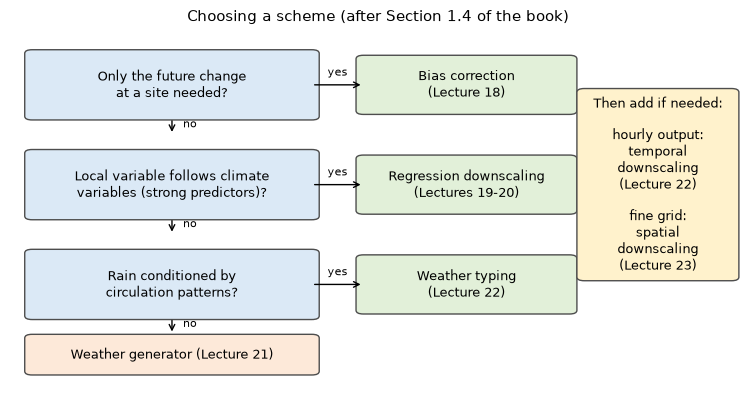

                                                                    project                                         core scheme                      add-ons
              Change in mean seasonal reservoir inflow, one site, 2070-2100                        Bias correction (Lecture 18)                         none
Daily temperature at a station for a crop model (strong link to reanalysis)             Regression downscaling (Lectures 19-20)                         none
                Rain at a hill station tied to monsoon circulation patterns Weather typing + stochastic model (Lectures 22, 21)                         none
                  Drought risk: thousands of random 30-year rainfall series                      Weather generator (Lecture 21)                         none
                               Hourly design storms, 20 km2 urban catchment                        Bias correction (Lecture 18)  + temporal downscaling (22)
                                           Distributed mod

In [3]:
def choose_scheme(change_only, predictors, circulation, subdaily, fine_grid):
    # the decision order of Section 1.4: change only -> predictors -> circulation or random -> add-ons
    if change_only:    core = "Bias correction (Lecture 18)"
    elif predictors:   core = "Regression downscaling (Lectures 19-20)"
    elif circulation:  core = "Weather typing + stochastic model (Lectures 22, 21)"
    else:              core = "Weather generator (Lecture 21)"
    add = [t for flag, t in ((subdaily, "temporal downscaling (22)"), (fine_grid, "spatial downscaling (23)")) if flag]
    return core, (" + " + ", ".join(add)) if add else "none"

fig, ax = plt.subplots(figsize=(9.5, 4.8)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0.0, 1)
qs = ["Only the future change\nat a site needed?", "Local variable follows climate\nvariables (strong predictors)?", "Rain conditioned by\ncirculation patterns?"]
outs = ["Bias correction\n(Lecture 18)", "Regression downscaling\n(Lectures 19-20)", "Weather typing\n(Lecture 22)"]
ys = [0.85, 0.58, 0.31]
def box(xc, yc, w, h, text, fc):
    ax.add_patch(mpatches.FancyBboxPatch((xc - w / 2, yc - h / 2), w, h, boxstyle="round,pad=0.01", fc=fc, ec="0.3"))
    ax.text(xc, yc, text, ha="center", va="center", fontsize=9)
for i, (q, o, y) in enumerate(zip(qs, outs, ys)):
    box(0.22, y, 0.38, 0.17, q, "#dbe9f6"); box(0.62, y, 0.28, 0.14, o, "#e2f0d9")
    ax.annotate("", xy=(0.48, y), xytext=(0.41, y), arrowprops=dict(arrowstyle="->")); ax.text(0.445, y + 0.025, "yes", ha="center", fontsize=8)
    ax.annotate("", xy=(0.22, y - 0.135), xytext=(0.22, y - 0.09), arrowprops=dict(arrowstyle="->")); ax.text(0.235, y - 0.115, "no", fontsize=8)
box(0.22, 0.12, 0.38, 0.09, "Weather generator (Lecture 21)", "#fde9d9")
box(0.88, 0.58, 0.20, 0.50, "Then add if needed:\n\nhourly output:\ntemporal\ndownscaling\n(Lecture 22)\n\nfine grid:\nspatial\ndownscaling\n(Lecture 23)", "#fff2cc")
ax.set_title("Choosing a scheme (after Section 1.4 of the book)", fontsize=11)
plt.show()

cases = [("Change in mean seasonal reservoir inflow, one site, 2070-2100", 1, 0, 0, 0, 0),
         ("Daily temperature at a station for a crop model (strong link to reanalysis)", 0, 1, 0, 0, 0),
         ("Rain at a hill station tied to monsoon circulation patterns", 0, 0, 1, 0, 0),
         ("Drought risk: thousands of random 30-year rainfall series", 0, 0, 0, 0, 0),
         ("Hourly design storms, 20 km2 urban catchment", 1, 0, 0, 1, 0),
         ("Distributed model on a 1 km grid", 1, 0, 0, 0, 1)]
print(pd.DataFrame([(c[0], *choose_scheme(*c[1:])) for c in cases], columns=["project", "core scheme", "add-ons"]).to_string(index=False))

# 3.1 GCM data (Ch. 3.1)

GCM output for the IPCC assessments comes from the CMIP experiments and is downloaded from data portals after a login. A file name carries the description of the data. The book's pattern is `variable_frequency_model_scenario_ensemble_period.nc`. A CMIP6-style example is `pr_day_<model>_ssp245_r1i1p1f1_gn_20150101-21001230.nc`: `pr` is precipitation, `day` is daily, then the model name, the scenario, the ensemble member, the grid label and the period. The end date `1230` hints at a 360-day calendar.

The format is mostly **NetCDF** (`.nc`), an open standard that can be read from C, Fortran, R, Matlab, Java and Python (Lecture 15 uses `xarray`). Three checks before using a file:

- **Units.** GCM rain is a flux in kg m$^{-2}$ s$^{-1}$ and temperature is in K; observations are in mm/day and $^\circ$C. Water is 1000 kg m$^{-3}$, so 1 kg m$^{-2}$ is a layer 1 mm deep, and a day has 86 400 s:

  $$P\ [\mathrm{mm/day}] = pr_f \times 86\,400, \qquad T\ [^\circ\mathrm{C}] = T\ [\mathrm{K}] - 273.15 .$$

- **Calendar.** Some models use a **360-day** year of twelve 30-day months, others a 365-day year. A rate in mm/day does not depend on the calendar, but a total does: a model month has 30 days.
- **Grid.** Each model has its own grid (the book's Table 3.1 lists them), so the box that contains the catchment must be chosen, for example the nearest cell centre.

# 3.2 Reanalysis data (Ch. 3.2)

A reanalysis describes the past climate by combining a model with observations, for air temperature, pressure, wind and surface fields, worldwide and over decades. A regular GCM does not simulate the real past weather, only a virtual weather. So the relation between a local variable and large-scale variables is fitted with **observations and reanalysis**; then GCM output *replaces* the reanalysis to predict the future.

# 3.3 RCM data (Ch. 3.3)

RCMs are forced by time-dependent boundary conditions from a GCM or reanalysis. **CORDEX** divides the globe into domains (South Asia, East Asia, Europe, ...) and provides RCM output. Statistical downscaling should still be applied to RCM output when a site is needed, and an hourly step is still too coarse for small urban watersheds.

| Data | What it is | Role in downscaling |
|:--|:--|:--|
| GCM | global model, free-running | future projections; its own weather and bias |
| Reanalysis | model corrected by observations | predictors fitted to real weather |
| RCM (CORDEX) | regional model on a finer grid | finer fields, still biased |
| Observations | gauge or gridded measurements | the target |

*What this means for hydrology: a wrong unit or calendar gives an error of a factor 86 400 or of a few percent in every flood and water-balance number that follows.*

# Worked example (by hand)

The book's chapters have no numbered example, so we follow its order of ideas with new numbers: effective temperature (Section 1.2), unit and calendar conversion of GCM data (Section 3.1), and choice of scheme (Section 1.4).

**Problem.** (a) A planet has $S_0=1370$ W/m$^2$ and $\alpha_p=0.25$; find $T_e$ in $^\circ$C. (b) A GCM cell gives monthly mean rain fluxes in a 360-day calendar (every month 30 days): June $3.0\times10^{-5}$, July $1.1\times10^{-4}$, August $9.0\times10^{-5}$ kg m$^{-2}$ s$^{-1}$; the gauge gives 3.4, 8.1 and 7.5 mm/day. The model's July temperature is 301.4 K, the gauge's is 26.9 $^\circ$C. Compare the season rain totals and the temperatures. (c) A farm board needs *daily* future temperature at one station that follows reanalysis temperature closely ($r=0.9$). Which scheme?

**Step 1 (Eq. 1.2).** With $\sigma=5.67\times10^{-8}$: $(1-0.25)\times1370=1027.5$; $4\sigma=2.268\times10^{-7}$; ratio $=4.530\times10^{9}$; fourth root $T_e=259.4$ K; $259.4-273.15=-13.7$ $^\circ$C. (Absorbed sunlight balances emitted heat; the fourth root undoes $T^4$.)

**Step 2 (flux to depth).** 1 kg m$^{-2}$ is 1 mm, a day has 86 400 s: June $3.0\times10^{-5}\times86\,400=2.592$; July $1.1\times10^{-4}\times86\,400=9.504$; August $9.0\times10^{-5}\times86\,400=7.776$ mm/day.

**Step 3 (totals).** Rate times 30 days: model $77.76,\ 285.12,\ 233.28$, sum $596.16$ mm; gauge $102,\ 243,\ 225$, sum $570$ mm (same 30 days so the totals are comparable).

**Step 4 (bias).** Rain uses the ratio: $b_P=596.16/570=1.046$ (4.6 % too wet, $+26.16$ mm); by month $0.76,\ 1.17,\ 1.04$. Temperature uses the difference, in $^\circ$C first: $301.4-273.15=28.25$; $b_T=28.25-26.9=+1.35$ K.

**Step 5 (Section 1.4).** Only the future change needed? No, a daily series. Does the local variable follow climate variables? Yes, $r=0.9$. So **regression downscaling** with reanalysis predictors (Lecture 19).

**Answer.** $T_e=-13.7^\circ$C; $b_P=1.046$; $b_T=+1.35$ K; regression downscaling. *Interpretation: the 4.6 % season bias hides monthly errors of $-24$ %, $+17$ % and $+4$ %, because a wet month cancels a dry one.*

In [4]:
# the same by-hand example in code (compare with sheet Hand_example)
S0, alpha_p, sigma = 1370.0, 0.25, 5.67e-8
T_e = ((1 - alpha_p) * S0 / (4 * sigma)) ** 0.25
print(f"T_e = {T_e:.1f} K = {T_e - 273.15:.1f} degC")
pr_f_ex = np.array([3.0e-5, 1.1e-4, 9.0e-5])         # kg m-2 s-1, Jun, Jul, Aug
P_o_ex = np.array([3.4, 8.1, 7.5])                    # mm/day
days = 30                                             # 360-day calendar
P_m_ex = pr_f_ex * 86400
tot_m, tot_o = P_m_ex * days, P_o_ex * days
print("P_m [mm/day]       :", P_m_ex.round(3))
print("model totals [mm]  :", tot_m.round(2), " sum", tot_m.sum().round(2))
print("gauge totals [mm]  :", tot_o.round(2), " sum", tot_o.sum().round(2))
print(f"b_P season = {tot_m.sum() / tot_o.sum():.3f}  (+{tot_m.sum() - tot_o.sum():.2f} mm);  by month {(P_m_ex / P_o_ex).round(2)}")
T_m_ex = 301.4 - 273.15
print(f"T_m = {T_m_ex:.2f} degC,  b_T = {T_m_ex - 26.9:+.2f} K")
print("scheme:", choose_scheme(change_only=0, predictors=1, circulation=0, subdaily=0, fine_grid=0)[0])

T_e = 259.4 K = -13.7 degC
P_m [mm/day]       : [2.592 9.504 7.776]
model totals [mm]  : [ 77.76 285.12 233.28]  sum 596.16
gauge totals [mm]  : [102. 243. 225.]  sum 570.0
b_P season = 1.046  (+26.16 mm);  by month [0.76 1.17 1.04]
T_m = 28.25 degC,  b_T = +1.35 K
scheme: Regression downscaling (Lectures 19-20)


# Hands-on: a synthetic GCM, reanalysis and gauge

Now the same ideas on daily data for 10 years where we **know the truth**. The cell below builds a gauge series (real calendar), a reanalysis series that follows the gauge weather, and a 4 $\times$ 4 grid of 2.5$^\circ$ GCM cells (360-day calendar, units kg m$^{-2}$ s$^{-1}$ and K). The GCM has its own weather, a monsoon 15 days late, too many light-rain days and a temperature 2 K too warm. You do not need to read the generator; to use real data, replace `P_o`, `P_r` and the GCM arrays by series from gauges or IMD rainfall, ERA5 and a CMIP6 file (for example with `xarray`, Lecture 15).

In [5]:
# synthetic "world" for Lecture 16 (shared by the notebook cell and the workbook builder)
import numpy as np, pandas as pd
from scipy.stats import norm, gamma
from scipy.signal import lfilter

rng = np.random.default_rng(16)
YEARS = np.arange(2001, 2011)                              # 10 years

def ar1(shape, rho):
    """unit-variance AR(1) noise along axis 0 (gives day-to-day persistence)"""
    return lfilter([np.sqrt(1 - rho**2)], [1, -rho], rng.standard_normal(shape), axis=0)

def season(f, peak, width):                                # monsoon shape, f = day of year on a 365-day scale
    return np.exp(-0.5 * ((f - peak) / width) ** 2)

def rain_from_z(z, p, mean_amt, shape=0.8):
    """z -> daily rain [mm/day]: wet with probability p, gamma amount when wet"""
    u = norm.cdf(z); wet = u > 1 - p
    q = np.clip((u - (1 - p)) / p, 1e-9, 1 - 1e-9)
    return np.where(wet, gamma.ppf(q, shape, scale=mean_amt / shape), 0.0)

# calendars: observations and reanalysis use the real calendar, the GCM a 360-day calendar
t_std = pd.date_range("2001-01-01", "2010-12-31", freq="D")
f_std = t_std.day_of_year.values * 365.0 / np.where(t_std.is_leap_year, 366.0, 365.0)
k = np.arange(360 * len(YEARS))
g_year, g_doy = 2001 + k // 360, k % 360 + 1
g_month, g_day = (g_doy - 1) // 30 + 1, (g_doy - 1) % 30 + 1
f_360 = g_doy * 365.0 / 360.0

# observations at the catchment (real weather)
z_o = ar1(len(t_std), 0.4); zT_o = ar1(len(t_std), 0.7)
M = season(f_std, 200, 35)
P_o = rain_from_z(z_o, 0.12 + 0.68 * M, 2.0 + 7.0 * M)                          # mm/day
T_o = 18 + 9 * np.cos(2 * np.pi * (f_std - 190) / 365) + 2.0 * zT_o            # degC
# reanalysis: its weather follows the real weather (correlated), small bias
z_r = 0.85 * z_o + np.sqrt(1 - 0.85**2) * ar1(len(t_std), 0.4)
zT_r = 0.92 * zT_o + np.sqrt(1 - 0.92**2) * ar1(len(t_std), 0.7)
P_r = rain_from_z(z_r, 0.15 + 0.66 * M, 2.2 + 7.0 * M)
T_r = T_o + 0.3 + 0.8 * (zT_r - zT_o)
# GCM: 4 x 4 coarse cells, 2.5 degree, own weather, monsoon 15 days late, too many light-rain days, 2 K too warm
glat = np.array([27.5, 30.0, 32.5, 35.0]); glon = np.array([72.5, 75.0, 77.5, 80.0])
Mg = season(f_360, 215, 40)[:, None, None]
shared = ar1(len(k), 0.4)[:, None, None]; sharedT = ar1(len(k), 0.7)[:, None, None]
zc = np.sqrt(0.7) * shared + np.sqrt(0.3) * ar1((len(k), 4, 4), 0.4)
zT = np.sqrt(0.7) * sharedT + np.sqrt(0.3) * ar1((len(k), 4, 4), 0.7)
gcm_pr_f = rain_from_z(zc, 0.28 + 0.47 * Mg, 1.7 + 6.8 * Mg) / 86400.0          # kg m-2 s-1
gcm_tas = 20 + 7.5 * np.cos(2 * np.pi * (f_360 - 190) / 365)[:, None, None] + 2.0 * zT + 273.15   # K

In [6]:
# 1) pick the GCM cell that contains the catchment (31.75 N, 77.0 E): the nearest cell centre
i, j = np.abs(glat - 31.75).argmin(), np.abs(glon - 77.0).argmin()
ns = 111.2 * 2.5; ew = ns * np.cos(np.deg2rad(glat[i]))
print(f"cell centre {glat[i]} N, {glon[j]} E;  {ns:.0f} x {ew:.0f} km = {ns * ew:,.0f} km2; a 1000 km2 catchment is {100 * 1000 / (ns * ew):.1f} % of it")
pr_f_m, T_m_K = gcm_pr_f[:, i, j], gcm_tas[:, i, j]
print(f"raw GCM file values: pr_f_m mean {pr_f_m.mean():.2e} kg m-2 s-1, T_m_K mean {T_m_K.mean():.2f} K")

# 2) units and calendar
P_m, T_m = pr_f_m * 86400, T_m_K - 273.15
print(f"after conversion   : P_m mean {P_m.mean():.2f} mm/day, T_m mean {T_m.mean():.2f} degC")
print(f"GCM year has {len(P_m) // len(YEARS)} days; annual total {P_m.mean() * 360:.0f} mm (360 days) but {P_m.mean() * 365:.0f} mm if we wrongly use 365")
g_date = pd.to_datetime(pd.DataFrame({"year": g_year, "month": g_month, "day": g_day}), errors="coerce")
print("GCM days that do not exist in the real calendar (29 and 30 February):", int(g_date.isna().sum()), "of", len(g_date))

P_m_date = pd.Series(P_m, index=g_date); P_m_date = P_m_date[P_m_date.index.notna()]     # GCM series on real dates

# 3) monthly means (calendar-independent), rounded as in the Data sheet
mo_o, mo_g = t_std.month, g_month
data = pd.DataFrame({
    "P_o": pd.Series(P_o, index=mo_o).groupby(level=0).mean().round(3),
    "pr_f_m": pd.Series(pr_f_m, index=mo_g).groupby(level=0).mean().map(lambda x: float(f"{x:.4g}")),
    "T_o": pd.Series(T_o, index=mo_o).groupby(level=0).mean().round(2),
    "T_m_K": pd.Series(T_m_K, index=mo_g).groupby(level=0).mean().round(2)})
data.index.name = "month"
data["P_m"] = data.pr_f_m * 86400
data["T_m"] = data.T_m_K - 273.15
data["b_T"] = data.T_m - data.T_o
print(data.round({"P_m": 3, "T_m": 2, "b_T": 2}).to_string(formatters={"pr_f_m": "{:.3e}".format}))
b_P = data.P_m.sum() / data.P_o.sum()
print(f"\nrain bias b_P = {b_P:.3f};  mean temperature bias b_T = {data.b_T.mean():+.2f} K")
days_o = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
print(f"annual total: gauge {(data.P_o * days_o).sum():.1f} mm (real month lengths), GCM {(data.P_m * 30).sum():.1f} mm (30-day months)")

cell centre 32.5 N, 77.5 E;  278 x 234 km = 65,181 km2; a 1000 km2 catchment is 1.5 % of it
raw GCM file values: pr_f_m mean 2.13e-05 kg m-2 s-1, T_m_K mean 293.16 K
after conversion   : P_m mean 1.84 mm/day, T_m mean 20.01 degC
GCM year has 360 days; annual total 662 mm (360 days) but 671 mm if we wrongly use 365
GCM days that do not exist in the real calendar (29 and 30 February): 18 of 3600
         P_o    pr_f_m    T_o   T_m_K    P_m    T_m   b_T
month                                                    
1      0.128 6.721e-06   9.05  286.11  0.581  12.96  3.91
2      0.297 3.477e-06  10.48  287.38  0.300  14.23  3.75
3      0.256 5.771e-06  14.44  290.57  0.499  17.42  2.98
4      0.333 5.534e-06  18.99  293.62  0.478  20.47  1.48
5      0.816 1.463e-05  23.64  297.88  1.264  24.73  1.09
6      3.463 3.082e-05  26.11  299.82  2.663  26.67  0.56
7      7.269 6.261e-05  26.86  300.66  5.410  27.51  0.65
8      4.290 6.283e-05  25.05  299.03  5.429  25.88  0.83
9      1.145 4.091e-05 

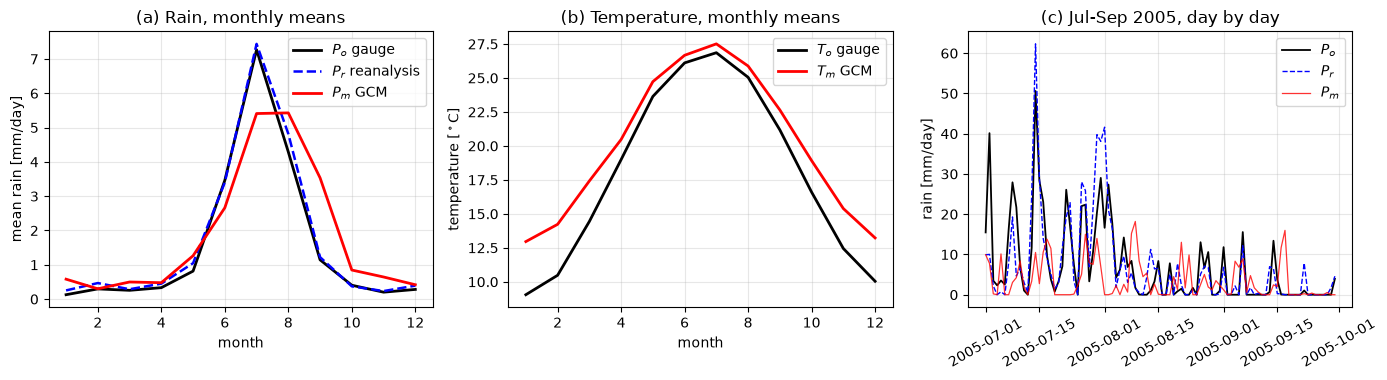

daily correlation with the gauge: reanalysis 0.80, GCM 0.01


In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axs[0]
ax.plot(data.index, data.P_o, "k-", lw=2, label="$P_o$ gauge")
ax.plot(data.index, pd.Series(P_r, index=mo_o).groupby(level=0).mean(), "b--", lw=1.8, label="$P_r$ reanalysis")
ax.plot(data.index, data.P_m, "r-", lw=2, label="$P_m$ GCM")
ax.set(xlabel="month", ylabel="mean rain [mm/day]", title="(a) Rain, monthly means"); ax.legend(); ax.grid(alpha=0.3)
ax = axs[1]
ax.plot(data.index, data.T_o, "k-", lw=2, label="$T_o$ gauge"); ax.plot(data.index, data.T_m, "r-", lw=2, label="$T_m$ GCM")
ax.set(xlabel="month", ylabel="temperature [$^\\circ$C]", title="(b) Temperature, monthly means"); ax.legend(); ax.grid(alpha=0.3)
ax = axs[2]
s = (t_std >= "2005-07-01") & (t_std <= "2005-09-30")
ax.plot(t_std[s], P_o[s], "k", lw=1.3, label="$P_o$"); ax.plot(t_std[s], P_r[s], "b--", lw=1, label="$P_r$")
gs = P_m_date[(P_m_date.index >= "2005-07-01") & (P_m_date.index <= "2005-09-30")]
ax.plot(gs.index, gs.values, "r", lw=0.9, alpha=0.8, label="$P_m$")
ax.set(ylabel="rain [mm/day]", title="(c) Jul-Sep 2005, day by day"); ax.legend(); ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); plt.show()

# day-by-day agreement, matched by date, after removing each series' own monthly means
d = pd.DataFrame({"P_o": P_o, "P_r": P_r}, index=t_std).join(P_m_date.rename("P_m"))
d = d[~d.index.duplicated()].dropna()
an = d - d.groupby(d.index.month).transform("mean")
print(f"daily correlation with the gauge: reanalysis {an.P_o.corr(an.P_r):.2f}, GCM {an.P_o.corr(an.P_m):.2f}")

Reading the figure and numbers:

- **(a)** The GCM monsoon peaks too late and runs wetter than the gauge, so the rain bias $b_P$ is above 1 and changes from month to month. A single number would hide this.
- **(b)** The GCM is too warm in every month, by about 2 K on average: $b_T$ is positive. Part of such a bias in real models is simply the box being lower than the catchment (the scale part of the gap).
- **(c)** The reanalysis rises and falls with the real storms; the GCM makes its own storms on other days. The daily correlation is high for the reanalysis and close to zero for the GCM. This is the timing part of the gap, and it is why reanalysis, not the GCM, is used to fit relations day by day.
- The 360-day year gives a total of the model's own year; using 365 days would add 1.4 % that the model never produced.

*What this means for hydrology: before any downscaling, check units, calendar and which cell you took, and look at the monthly bias; only then choose a scheme.*

## Summary

- A GCM box averages over terrain that a catchment resolves. The gap has three parts: **scale**, **bias** and **timing**.
- **GCM** (free-running, gives the future), **reanalysis** (follows real weather, gives predictors), **RCM** (finer, still biased) and **observations** (the target) play different roles.
- Convert GCM data first: flux $\times$ 86 400 = mm/day, K $-$ 273.15 = $^\circ$C, and use 30 days per month in a 360-day calendar.
- The families are regression (transfer function), weather generator and weather typing, plus bias correction, temporal and spatial downscaling. All statistical methods assume **stationarity**.
- The choice of scheme follows the output you need (Section 1.4 of the book).

## Check your understanding

1. A model gives $pr_f=2.0\times10^{-5}$ kg m$^{-2}$ s$^{-1}$ for a 30-day month. What are the daily rate in mm/day and the monthly total in mm?
2. Why is the day-by-day correlation between a free-running GCM and a gauge about zero, and why is that not a fault of the model? Which dataset do you use to fit a regression?
3. Choose a scheme for (a) the change in mean seasonal inflow of one reservoir by 2100, and (b) hourly design storms for a 20 km$^2$ urban catchment.

# Try it yourself

- Change the seed in `default_rng(16)` and rerun: how much do $b_P$ and $b_T$ change over 10 years?
- Take another GCM cell (change `i` and `j`) and compare its monthly $P_m$ with the cell above.
- In the spreadsheet sheet `Method_guide`, add your own project in the last row and read off the scheme.

```{note} Where this lecture differs from the book
- The book quotes GCM grids of 250 to 600 km (the AR5 models); current CMIP6 models have about 100 to 250 km, which is what this lecture uses.
- The footnote of the book's Table 3.1 gives T42 as "around 5.61" at the equator; T42 corresponds to about 2.8$^\circ$ (a 64 $\times$ 128 grid).
- The book quotes RCM resolution of 10 to 20 km; CORDEX South Asia is mostly 0.44$^\circ$ (about 50 km) and finer.
- The book's data links point to CMIP5 sites; CMIP6 data are now served through ESGF nodes.
- The book gives no calendar or unit conversions; Section 3.1 and the by-hand example add them because the hands-on part needs them.
```

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The structure and terms follow the reference book below; the explanations, synthetic data, code and figures here are our own.

**Main reference.** Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press. Chapter 1 (Sections 1.1 to 1.4: why downscale, the three statistical families, selection of a model scheme) and Chapter 3 (Sections 3.1 to 3.3: GCM, reanalysis and RCM data and formats).

**Further reading.** Maraun, D., et al. (2010). Precipitation downscaling under climate change. *Reviews of Geophysics, 48*, RG3003. &middot; Maraun, D., & Widmann, M. (2018). *Statistical Downscaling and Bias Correction for Climate Research*. Cambridge University Press. &middot; Eyring, V., et al. (2016). Overview of CMIP6 experimental design and organization. *Geoscientific Model Development, 9*, 1937&ndash;1958. &middot; Hersbach, H., et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society, 146*, 1999&ndash;2049.

All data are synthetic; the catchment and the model biases are illustrative. The spreadsheet formulas were checked against an independent Python calculation but not recalculated in desktop Excel. All figures are drawn for this course.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```